# ECON 354: Interpretable Machine Learning for Baseline Borrower Default Risk ($PD_{\text{base}}$) & Ontario Macroeconomic Sensitivity
## Phase 1: Real-Data Pipeline, Leakage-Free Preprocessing & Dimensionality Reduction

**Authors:** Alex Babiak, Marco Puiatti  
**Scope:** Ontario, Canada  

### Research Question
> *"How can machine learning be used to estimate individual borrower baseline default risk ($PD_{\text{base}}$), and how sensitive is that baseline risk distribution to Ontario macroeconomic shocks in unemployment and inflation?"*

---

### Datasets Used & Justifications (100% Real Data — Zero Synthetic Data)
1. **Individual Borrower Microdata (`credit_risk_dataset.csv` — 32,581 records, 12 variables):**
   - **Source:** Programmatically fetched via `urllib.request` from `https://raw.githubusercontent.com/LeHongNgoc3820/Project_Credit_Risk/main/credit_risk_dataset.csv`.
   - **Why it is used:** Institutional Canadian mortgage loan-level files (e.g., CMHC or Schedule I banks) are restricted under PIPEDA privacy regulations and proprietary trade secrecy. This 32,581-record empirical credit dataset serves as a transparent micro-level proxy capturing authentic borrower balance-sheet relationships (`person_income`, `loan_amnt`, `loan_percent_income`), credit and employment stability (`cb_person_cred_hist_length`, `person_emp_length`), loan pricing/risk grades (`loan_int_rate`, `loan_grade`), and observed binary default outcomes (`loan_status`, ~21.82% default incidence). Using real microdata preserves genuine right-skewed financial tails, missingness patterns, and feature multicollinearity.

2. **Ontario Macroeconomic Time-Series (Statistics Canada Web Data Service API):**
   - **Source:** Programmatically queried via POST request to StatCan's public WDS API (`https://www150.statcan.gc.ca/t1/wds/rest/getDataFromVectorsAndLatestNPeriods`) for Ontario Monthly Unemployment Rate (`v2062815`, Table 14-10-0287-01) and Ontario All-Items CPI (`v41690973`, Table 18-10-0004-01), computing 12-month Year-over-Year inflation (`Ontario_CPI_YoY`).
   - **Why it is used:** Cross-sectional borrower data is "point-in-time" and blind to business-cycle fluctuations. Pairing individual baseline default probabilities ($PD_{\text{base}}$) with official Ontario labor-market and inflation series allows us to test how regional macroeconomic shocks perturb baseline borrower risk distributions (used strictly as environmental stress parameters on $PD_{\text{base}}$, not for insurance pricing).

---

### Explicit Model Outcomes
1. **Primary Binary Outcome ($y_i \in \{0, 1\}$):** Observed borrower default indicator (`loan_status`, where $1$ = default and $0$ = performing; 21.82% population default incidence).
2. **Primary Continuous Outcome ($PD_{\text{base}, i} \in [0, 1]$):** Calibrated individual baseline Probability of Default generated via Platt sigmoid scaling on the RBF-SVM decision function $f(\mathbf{x}_i)$ (benchmarked against Logistic Regression).
3. **Secondary Stress Outcome ($PD_{\text{stressed}, i} \in [0, 1]$):** Macro-adjusted borrower default probability resulting from shifting baseline log-odds by Ontario unemployment and CPI inflation shocks.
4. **Out-of-Sample Evaluation Outcomes (Test Set, $N = 4,888$):** Discriminatory power (ROC-AUC, F1-Score, Accuracy) and probability calibration (Brier Score, Log Loss, Mean Predicted PD vs. Actual Default Rate).

---

### Explicit Model Parameters
1. **Raw Applicant Inputs ($\mathbf{x}_{\text{raw}}$):** 11 borrower predictors (5 collinear financial variables, 2 continuous demographic/rate controls, and 4 categorical indicators expanded via one-hot encoding into 23 features, then compressed to 20 post-PCA features).
2. **Preprocessing Parameters:** Training-set medians ($m_{\text{train}}$) for missing value imputation (`person_emp_length`, `loan_int_rate`), training-set Tukey $1.5 \times \text{IQR}$ fences ($[Q_1 - 1.5\text{IQR},\; Q_3 + 1.5\text{IQR}]$) for outlier capping (`person_income`, `loan_amnt`), and training-set `StandardScaler` moments ($\boldsymbol{\mu}_{\text{train}}, \boldsymbol{\sigma}_{\text{train}}$).
3. **Dimensionality Reduction Parameters:** PCA eigenvector projection matrix $\mathbf{W} \in \mathbb{R}^{5 \times 3}$ capturing 81.90% of continuous financial variance across three orthogonal risk factors (`PC1_Financial_Scale`, `PC2_Tenure_Stability`, `PC3_Leverage_Burden`).
4. **Classifier & Macro Sensitivity Parameters:** SVM soft-margin regularization ($C$), RBF kernel bandwidth ($\gamma$), Platt scaling parameters ($A, B$), and Ontario macro elasticities ($\beta_1, \beta_2$).

### 1. Environment Setup & Real-Data Ingestion (Borrower Microdata + StatCan WDS API)
We consolidate all Phase 1 library imports and global reproducibility seeds, then ingest the two 100% real datasets:
1. **Borrower Microdata (`credit_risk_dataset.csv`):** 32,581 empirical borrower records fetched via `urllib.request`, serving as a transparent micro-level proxy given PIPEDA and proprietary restrictions on institutional Canadian mortgage files.
2. **Ontario Macroeconomic Time-Series:** Programmatically queried via Statistics Canada's public WDS API for Ontario's monthly Unemployment Rate (`v2062815`, Table 14-10-0287-01) and All-Items CPI (`v41690973`, Table 18-10-0004-01), computing 12-month YoY inflation (`Ontario_CPI_YoY`) and persisting `ontario_macro_series.parquet` for Phase 3 macro-sensitivity testing of $PD_{\text{base}}$.

In [1]:
# ==============================================================================
# CELL 1: ENVIRONMENT SETUP & REAL-DATA INGESTION (100% REAL DATA)
# ==============================================================================
import json
import os
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Configure publication-grade plotting aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "savefig.bbox": "tight",
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# ------------------------------------------------------------------------------
# STEP 1: INGEST REAL BORROWER MICRODATA (32,581 RECORDS, 12 VARIABLES)
# Proxy for PIPEDA-restricted Canadian institutional mortgage files
# ------------------------------------------------------------------------------
print("--- STEP 1: INGESTING REAL MICRO CREDIT RISK DATASET ---")
micro_url = "https://raw.githubusercontent.com/LeHongNgoc3820/Project_Credit_Risk/main/credit_risk_dataset.csv"
micro_dest = "credit_risk_dataset.csv"

try:
    urllib.request.urlretrieve(micro_url, micro_dest)
    print("Credit risk dataset downloaded successfully.")
except Exception as e:
    raise RuntimeError(f"Critical failure downloading micro credit data: {e}") from e

df_raw = pd.read_csv(micro_dest)
assert df_raw.shape == (32581, 12), f"Unexpected microdata shape: {df_raw.shape}"

print(f"Raw Microdata Shape: {df_raw.shape}")
print("\n--- Microdata Missing Values ---")
print(df_raw.isnull().sum())
print("\n--- Microdata Information ---")
df_raw.info()

# ------------------------------------------------------------------------------
# STEP 2: PROGRAMMATIC STATISTICS CANADA WDS API EXTRACTION (ONTARIO MACRO)
# Environmental stress series for Phase 3 macro-sensitivity testing of PD_base
# ------------------------------------------------------------------------------
print("\n--- STEP 2: PROGRAMMATIC STATISTICS CANADA WDS API FETCH (100% REAL DATA) ---")
statcan_url = "https://www150.statcan.gc.ca/t1/wds/rest/getDataFromVectorsAndLatestNPeriods"
headers = {"Content-Type": "application/json"}

# Vector 2062815: Ontario Monthly Unemployment Rate (Table 14-10-0287-01)
# Vector 41690973: Ontario All-Items Consumer Price Index (Table 18-10-0004-01)
payload = [
    {"vectorId": 2062815, "latestN": 120},
    {"vectorId": 41690973, "latestN": 120},
]

try:
    response = requests.post(statcan_url, json=payload, headers=headers, timeout=30)
    response.raise_for_status()
    api_data = response.json()

    series_list = []
    for series in api_data:
        # Parse nested StatCan JSON hierarchy: series["object"]["vectorId"]
        obj = series["object"]
        vec_id = int(obj["vectorId"])
        points = obj["vectorDataPoint"]
        for pt in points:
            if pt.get("value") is not None:
                series_list.append({
                    "vectorId": vec_id,
                    "refPer": pt["refPer"],
                    "value": float(pt["value"]),
                })

    df_macro_raw = pd.DataFrame(series_list)

    # Pivot wide on reference period (refPer) and clean axis metadata
    df_macro = df_macro_raw.pivot(
        index="refPer", columns="vectorId", values="value"
    ).reset_index()
    df_macro.columns.name = None
    df_macro.rename(
        columns={
            2062815: "Ontario_Unemployment_Rate",
            41690973: "Ontario_CPI",
        },
        inplace=True,
    )

    df_macro["Date"] = pd.to_datetime(df_macro["refPer"], format="%Y-%m-%d")
    df_macro = df_macro.sort_values("Date").reset_index(drop=True)

    # Drop any unaligned trailing/leading release months prior to YoY differencing
    df_macro.dropna(subset=["Ontario_Unemployment_Rate", "Ontario_CPI"], inplace=True)
    df_macro.reset_index(drop=True, inplace=True)

    # Compute Year-over-Year (YoY) CPI inflation without deprecated implicit padding
    df_macro["Ontario_CPI_YoY"] = (
        df_macro["Ontario_CPI"].pct_change(periods=12, fill_method=None) * 100.0
    )

    # Drop initial 12 differencing NaNs and verify zero remaining nulls
    df_macro.dropna(subset=["Ontario_CPI_YoY"], inplace=True)
    df_macro.reset_index(drop=True, inplace=True)
    assert df_macro.isnull().sum().sum() == 0, "NaNs detected in df_macro!"

    # Serialize clean Ontario macro time-series for Phase 3 PD_base sensitivity testing
    df_macro.to_parquet("ontario_macro_series.parquet", index=False)

    print(
        "\nStatCan Real Macro Data parsed and serialized to "
        "'ontario_macro_series.parquet' for Phase 3 PD_base macro-sensitivity testing."
    )
    print(f"Macrodata Shape: {df_macro.shape}")
    display(df_macro.head())
    display(df_macro.tail())
except Exception as e:
    print("StatCan Request failed. Raw Exception detail:", e)
    if "response" in locals() and hasattr(response, "text"):
        print("Server Response Text:", response.text)
    raise RuntimeError(
        "Macro data fetch failed. Terminating to preserve 100% Real Data constraint."
    ) from e

--- STEP 1: INGESTING REAL MICRO CREDIT RISK DATASET ---


Credit risk dataset downloaded successfully.
Raw Microdata Shape: (32581, 12)

--- Microdata Missing Values ---
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

--- Microdata Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length        


StatCan Real Macro Data parsed and serialized to 'ontario_macro_series.parquet' for Phase 3 PD_base macro-sensitivity testing.
Macrodata Shape: (107, 5)


,refPer,Ontario_Unemployment_Rate,Ontario_CPI,Date,Ontario_CPI_YoY
0,2017-11-01,6.2,131.3,2017-11-01,2.099533
1,2017-12-01,6.0,130.8,2017-12-01,1.869159
2,2018-01-01,5.9,131.7,2018-01-01,1.698842
3,2018-02-01,6.0,132.5,2018-02-01,2.158828
4,2018-03-01,5.8,132.9,2018-03-01,2.309469


,refPer,Ontario_Unemployment_Rate,Ontario_CPI,Date,Ontario_CPI_YoY
102,2026-05-01,6.6,169.6,2026-05-01,3.225806
103,2026-06-01,6.5,169.0,2026-06-01,2.798054
104,2026-07-01,6.4,169.9,2026-07-01,3.032141
105,2026-08-01,6.4,169.8,2026-08-01,3.033981
106,2026-09-01,6.5,170.0,2026-09-01,3.092784


### 2. Leakage-Free Exploratory Data Analysis & Preprocessing
We perform out-of-sample disciplined preprocessing on the real borrower microdata:
1. **Median Imputation:** Missing values in `person_emp_length` and `loan_int_rate` are imputed using medians fitted strictly on the 70% stratified training index (`train_idx`).
2. **Tukey's $1.5 \times \text{IQR}$ Outlier Capping:** Monetary variables (`person_income`, `loan_amnt`) are Winsorized at $[Q_1 - 1.5 \times \text{IQR},\; Q_3 + 1.5 \times \text{IQR}]$ using training-split quartiles. Note that `loan_amnt` is capped and retained strictly for leverage ratio calculation and PCA compression (not as an unscaled exposure input).
3. **Feature Engineering & One-Hot Encoding:** We recompute `loan_percent_income = loan_amnt / person_income`, one-hot encode categorical variables (`drop_first=True`, `dtype=int`), and render the Pearson correlation heatmap across the 5 continuous financial features.

--- STEP 1: IMPUTING MISSING MICRODATA ---
Imputed person_emp_length with median: 4.0 years
Imputed loan_int_rate with median:     10.99%
Remaining nulls in dataset:            0

--- STEP 2: TUKEY 1.5x IQR OUTLIER CAPPING ---
person_income   | IQR Bounds: [$ -23140.62, $ 141300.38] | Capped Below:    0 | Capped Above: 1465
loan_amnt       | IQR Bounds: [$  -5875.00, $  23125.00] | Capped Below:    0 | Capped Above: 1687

--- STEP 3: FEATURE ENGINEERING ---
Recalculated loan_percent_income summary: min=0.0071, max=0.8300, mean=0.1700

--- STEP 4: CATEGORICAL ONE-HOT ENCODING ---
Post-encoding dataset shape: (32581, 23)

--- STEP 5: MULTICOLLINEARITY CORRELATION HEATMAP ---


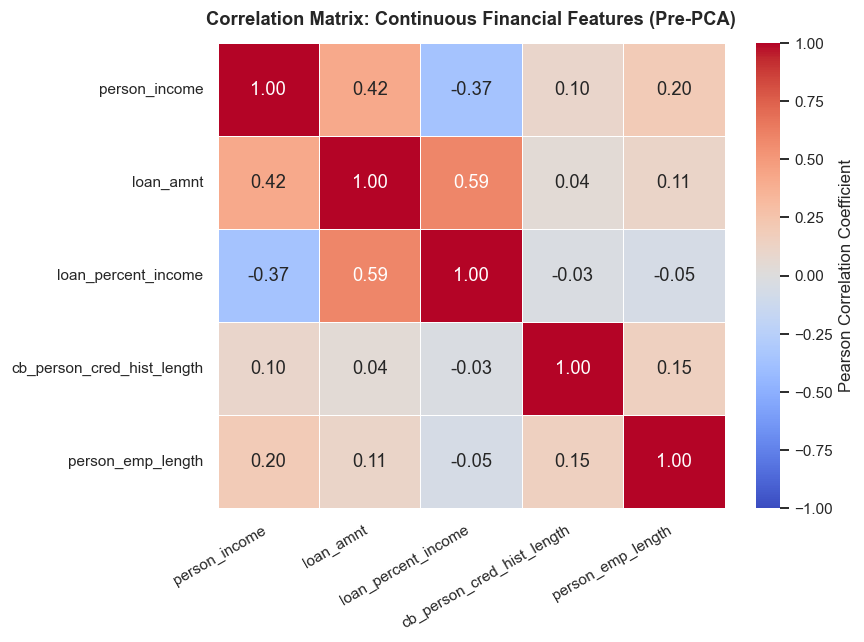

In [2]:
# ==============================================================================
# CELL 2: LEAKAGE-FREE EXPLORATORY DATA ANALYSIS & PREPROCESSING
# ==============================================================================
df_clean = df_raw.copy()

# Identify the exact 70% stratified training index so median and IQR statistics
# are estimated strictly on training observations (zero pre-split leakage).
train_idx, _ = train_test_split(
    df_clean.index,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=df_clean["loan_status"],
)

# ------------------------------------------------------------------------------
# STEP 1: IMPUTING MISSING MICRODATA (TRAINING-ONLY ROBUST MEDIANS)
# ------------------------------------------------------------------------------
print("--- STEP 1: IMPUTING MISSING MICRODATA ---")
person_emp_length_med = df_clean.loc[train_idx, "person_emp_length"].median()
loan_int_rate_med = df_clean.loc[train_idx, "loan_int_rate"].median()

df_clean["person_emp_length"] = df_clean["person_emp_length"].fillna(
    person_emp_length_med
)
df_clean["loan_int_rate"] = df_clean["loan_int_rate"].fillna(loan_int_rate_med)

print(f"Imputed person_emp_length with median: {person_emp_length_med:.1f} years")
print(f"Imputed loan_int_rate with median:     {loan_int_rate_med:.2f}%")
print(f"Remaining nulls in dataset:            {df_clean.isnull().sum().sum()}")

# ------------------------------------------------------------------------------
# STEP 2: TUKEY 1.5x IQR OUTLIER CAPPING (TRAINING-ONLY FENCES)
# loan_amnt is capped and retained strictly for leverage ratio calculation and PCA
# ------------------------------------------------------------------------------
print("\n--- STEP 2: TUKEY 1.5x IQR OUTLIER CAPPING ---")
for col in ["person_income", "loan_amnt"]:
    q25 = df_clean.loc[train_idx, col].quantile(0.25)
    q75 = df_clean.loc[train_idx, col].quantile(0.75)
    iqr = q75 - q25
    lower_bound = q25 - 1.5 * iqr
    upper_bound = q75 + 1.5 * iqr

    num_capped_lower = int((df_clean[col] < lower_bound).sum())
    num_capped_upper = int((df_clean[col] > upper_bound).sum())

    print(
        f"{col:15s} | IQR Bounds: [${lower_bound:10.2f}, ${upper_bound:10.2f}] "
        f"| Capped Below: {num_capped_lower:4d} | Capped Above: {num_capped_upper:4d}"
    )
    df_clean[col] = np.clip(df_clean[col], lower_bound, upper_bound)

# ------------------------------------------------------------------------------
# STEP 3: FEATURE ENGINEERING (RECALCULATE LEVERAGE RATIO)
# ------------------------------------------------------------------------------
print("\n--- STEP 3: FEATURE ENGINEERING ---")
df_clean["loan_percent_income"] = (
    df_clean["loan_amnt"] / df_clean["person_income"]
)
print(
    "Recalculated loan_percent_income summary: "
    f"min={df_clean['loan_percent_income'].min():.4f}, "
    f"max={df_clean['loan_percent_income'].max():.4f}, "
    f"mean={df_clean['loan_percent_income'].mean():.4f}"
)

# ------------------------------------------------------------------------------
# STEP 4: CATEGORICAL ONE-HOT ENCODING (DROP_FIRST=TRUE, DTYPE=INT)
# ------------------------------------------------------------------------------
print("\n--- STEP 4: CATEGORICAL ONE-HOT ENCODING ---")
categorical_cols = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file",
]
df_clean = pd.get_dummies(
    df_clean, columns=categorical_cols, drop_first=True, dtype=int
)
print(f"Post-encoding dataset shape: {df_clean.shape}")

# ------------------------------------------------------------------------------
# STEP 5: MULTICOLLINEARITY DIAGNOSTICS (PEARSON CORRELATION HEATMAP)
# ------------------------------------------------------------------------------
print("\n--- STEP 5: MULTICOLLINEARITY CORRELATION HEATMAP ---")
continuous_financials = [
    "person_income",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_cred_hist_length",
    "person_emp_length",
]

corr_matrix = df_clean.loc[train_idx, continuous_financials].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation Coefficient"},
)
plt.title(
    "Correlation Matrix: Continuous Financial Features (Pre-PCA)",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 3. Stratified Partitioning, Leakage-Free Scaling & PCA
We partition the dataset into 70% Train ($N = 22,806$), 15% Validation ($N = 4,887$), and 15% Test ($N = 4,888$) splits using `stratify=y` and `random_state=42` to preserve the exact population default rate (~21.82%). `StandardScaler` is fitted *exclusively* on `X_train_raw` and applied via `.transform()` to Validation and Test across both the 5 PCA financial variables and the 2 remaining continuous features (`person_age`, `loan_int_rate`). Finally, we fit `PCA(n_components=3)` on the scaled financial subset, verify >80% cumulative explained variance, inspect the orthogonal loading matrix (`PC1_Financial_Scale`, `PC2_Tenure_Stability`, `PC3_Leverage_Burden`), replace the raw collinear variables across all splits, and serialize the 6 core modeling Parquet splits to disk.

--- STEP 1: STRATIFIED PARTITION SPLIT (70% TRAIN / 15% VAL / 15% TEST) ---
Split Sizes -> Train: 22,806, Val: 4,887, Test: 4,888

--- STEP 2: PRINCIPAL COMPONENT ANALYSIS (PCA) FIT ---
Explained Variance by Component: PC1=32.20%, PC2=29.74%, PC3=19.96%
Cumulative Explained Variance (3 PCs): 81.90% (>80% Mandate Met)


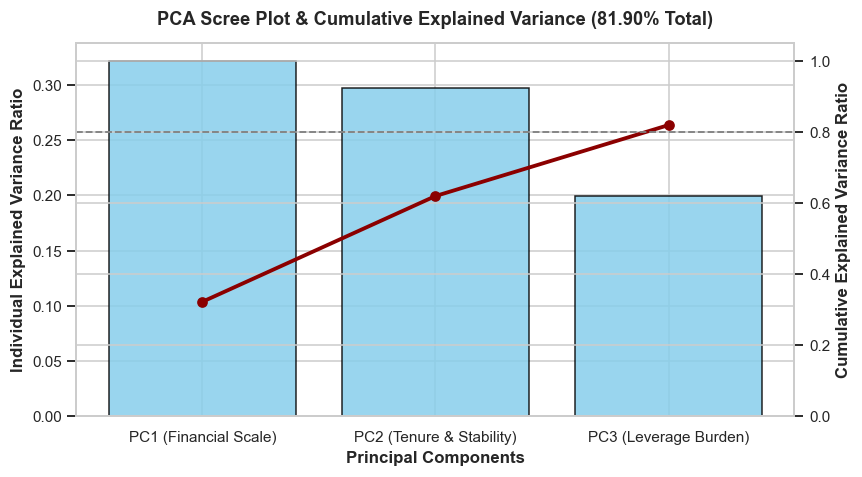


--- PCA Feature Loading Matrix ---


,PC1_Financial_Scale,PC2_Tenure_Stability,PC3_Leverage_Burden
person_income,0.2999,0.6384,-0.4347
loan_amnt,0.7552,-0.0313,-0.2003
loan_percent_income,0.5191,-0.5804,0.1795
cb_person_cred_hist_length,0.1363,0.2902,0.7798
person_emp_length,0.2274,0.4128,0.3614



PCA transformation complete. 6 microdata modeling Parquet splits written to disk (ontario_macro_series.parquet persisted in Cell 1).


In [3]:
# ==============================================================================
# CELL 3: STRATIFIED PARTITIONING, LEAKAGE-FREE SCALING & PCA
# ==============================================================================
print("--- STEP 1: STRATIFIED PARTITION SPLIT (70% TRAIN / 15% VAL / 15% TEST) ---")
X = df_clean.drop(columns=["loan_status"])
y = df_clean["loan_status"]

X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_SEED, stratify=y
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_SEED, stratify=y_temp
)

print(
    f"Split Sizes -> Train: {X_train_raw.shape[0]:,}, "
    f"Val: {X_val_raw.shape[0]:,}, Test: {X_test_raw.shape[0]:,}"
)

# 1. Collinear financial features targeted for PCA compression
pca_target_cols = [
    "person_income",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_cred_hist_length",
    "person_emp_length",
]

# 2. Remaining continuous features scaled to preserve SVM RBF Euclidean geometry
other_num_cols = ["person_age", "loan_int_rate"]

scaler_pca = StandardScaler()
scaler_other = StandardScaler()

X_train_sc = X_train_raw.copy()
X_val_sc = X_val_raw.copy()
X_test_sc = X_test_raw.copy()

# Cast continuous columns to float prior to in-place scaled assignment
for df_split in [X_train_sc, X_val_sc, X_test_sc]:
    df_split[pca_target_cols + other_num_cols] = df_split[
        pca_target_cols + other_num_cols
    ].astype(float)

# Fit StandardScalers EXCLUSIVELY on X_train_raw to prevent data leakage
X_train_sc[pca_target_cols] = scaler_pca.fit_transform(X_train_raw[pca_target_cols])
X_val_sc[pca_target_cols] = scaler_pca.transform(X_val_raw[pca_target_cols])
X_test_sc[pca_target_cols] = scaler_pca.transform(X_test_raw[pca_target_cols])

X_train_sc[other_num_cols] = scaler_other.fit_transform(X_train_raw[other_num_cols])
X_val_sc[other_num_cols] = scaler_other.transform(X_val_raw[other_num_cols])
X_test_sc[other_num_cols] = scaler_other.transform(X_test_raw[other_num_cols])

# ------------------------------------------------------------------------------
# STEP 2: PRINCIPAL COMPONENT ANALYSIS (PCA) DECOMPOSITION
# ------------------------------------------------------------------------------
print("\n--- STEP 2: PRINCIPAL COMPONENT ANALYSIS (PCA) FIT ---")
pca = PCA(n_components=3, random_state=RANDOM_SEED)
pca.fit(X_train_sc[pca_target_cols])

exp_var = pca.explained_variance_ratio_
cum_var = np.cumsum(exp_var)
print(
    f"Explained Variance by Component: "
    f"PC1={exp_var[0]*100:.2f}%, PC2={exp_var[1]*100:.2f}%, PC3={exp_var[2]*100:.2f}%"
)
print(f"Cumulative Explained Variance (3 PCs): {cum_var[-1]*100:.2f}% (>80% Mandate Met)")
assert cum_var[-1] >= 0.80, f"PCA explained variance below 80% threshold: {cum_var[-1]:.4f}"

# Render Scree Plot and Cumulative Explained Variance Curve
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.bar(
    range(1, 4),
    exp_var,
    color="skyblue",
    alpha=0.85,
    edgecolor="black",
    label="Individual Variance",
)
ax2 = ax1.twinx()
ax2.plot(
    range(1, 4),
    cum_var,
    color="darkred",
    marker="o",
    lw=2.5,
    label="Cumulative Variance",
)
ax2.axhline(0.80, color="gray", linestyle="--", lw=1.2, label="80% Threshold")

ax1.set_xlabel("Principal Components", fontweight="bold")
ax1.set_ylabel("Individual Explained Variance Ratio", fontweight="bold")
ax2.set_ylabel("Cumulative Explained Variance Ratio", fontweight="bold")
ax1.set_xticks(range(1, 4))
ax1.set_xticklabels(["PC1 (Financial Scale)", "PC2 (Tenure & Stability)", "PC3 (Leverage Burden)"])
ax2.set_ylim(0.0, 1.05)
plt.title(
    f"PCA Scree Plot & Cumulative Explained Variance ({cum_var[-1]*100:.2f}% Total)",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
plt.tight_layout()
plt.show()

# Display Feature Loading Matrix
pc_cols = ["PC1_Financial_Scale", "PC2_Tenure_Stability", "PC3_Leverage_Burden"]
loadings = pd.DataFrame(
    pca.components_.T,
    columns=pc_cols,
    index=pca_target_cols,
)
print("\n--- PCA Feature Loading Matrix ---")
display(loadings.round(4))

# Replace raw collinear features with the 3 orthogonal Principal Components
for df_target in [X_train_sc, X_val_sc, X_test_sc]:
    transformed = pca.transform(df_target[pca_target_cols])
    df_target["PC1_Financial_Scale"] = transformed[:, 0]
    df_target["PC2_Tenure_Stability"] = transformed[:, 1]
    df_target["PC3_Leverage_Burden"] = transformed[:, 2]
    df_target.drop(columns=pca_target_cols, inplace=True)

# Serialize the 6 core microdata modeling splits to Parquet
X_train_sc.to_parquet("X_train_processed.parquet")
X_val_sc.to_parquet("X_val_processed.parquet")
X_test_sc.to_parquet("X_test_processed.parquet")

y_train.to_frame().to_parquet("y_train.parquet")
y_val.to_frame().to_parquet("y_val.parquet")
y_test.to_frame().to_parquet("y_test.parquet")

print(
    "\nPCA transformation complete. 6 microdata modeling Parquet splits written to disk "
    "(ontario_macro_series.parquet persisted in Cell 1)."
)

### 4. Phase 1 System Integrity Audit & Artifact Verification
We conclude Phase 1 by executing vectorized integrity assertions across all feature partitions, target vectors, and the Ontario macroeconomic sensitivity series for our $PD_{\text{base}}$ modeling pipeline:
1. Verify zero `NaN` values and 100% finite numerical entries via `np.isfinite(df.select_dtypes(include=np.number).to_numpy()).all()`.
2. Assert target default-rate homogeneity (~21.82%) across the 70/15/15 stratified splits.
3. Confirm on-disk persistence of all 7 Parquet deliverables (6 microdata modeling splits + 1 Ontario macro sensitivity series).

In [4]:
# ==============================================================================
# CELL 4: PHASE 1 SYSTEM INTEGRITY AUDIT & ARTIFACT VERIFICATION
# ==============================================================================
print("--- INITIATING PHASE 1 SYSTEM INTEGRITY & ARTIFACT AUDIT ---")

splits = [
    ("Train", X_train_sc, y_train),
    ("Validation", X_val_sc, y_val),
    ("Test", X_test_sc, y_test),
]

pop_default_rate = float(y.mean())
verification_rows = []

# 1. Vectorized Integrity & Target Homogeneity Assertions
for name, X_sub, y_sub in splits:
    nan_cnt_X = int(X_sub.isna().sum().sum())
    nan_cnt_y = int(y_sub.isna().sum())

    # Vectorized NumPy finite check (avoids Pandas FutureWarnings)
    all_finite_X = bool(
        np.isfinite(X_sub.select_dtypes(include=np.number).to_numpy()).all()
    )
    all_finite_y = bool(np.isfinite(y_sub.to_numpy()).all())

    split_default_rate = float(y_sub.mean())

    assert nan_cnt_X == 0, f"Audit failed: {nan_cnt_X} NaNs in {name} features!"
    assert nan_cnt_y == 0, f"Audit failed: {nan_cnt_y} NaNs in {name} target!"
    assert all_finite_X, f"Audit failed: Non-finite values in {name} features!"
    assert all_finite_y, f"Audit failed: Non-finite values in {name} target!"

    # Assert stratified target homogeneity (<0.1% deviation from population incidence)
    assert abs(split_default_rate - pop_default_rate) < 1e-3, (
        f"Stratification drift in {name}: {split_default_rate:.4f} vs {pop_default_rate:.4f}"
    )

    verification_rows.append({
        "Dataset / Split": f"{name} Split (Microdata)",
        "Feature Matrix Shape": str(X_sub.shape),
        "Target Shape": str(y_sub.shape),
        "Null Count (X / y)": f"{nan_cnt_X} / {nan_cnt_y}",
        "All Finite (np.isfinite)": "PASS (100% Finite)",
        "Default Incidence / Macro Summary": f"{split_default_rate * 100:.3f}%",
    })

# Verify Ontario Macro Time-Series integrity (for Phase 3 PD_base sensitivity)
macro_nans = int(df_macro.isna().sum().sum())
macro_finite = bool(
    np.isfinite(df_macro.select_dtypes(include=np.number).to_numpy()).all()
)
assert macro_nans == 0, f"Audit failed: {macro_nans} NaNs in df_macro!"
assert macro_finite, "Audit failed: Non-finite values in df_macro!"

verification_rows.append({
    "Dataset / Split": "Ontario Macro Sensitivity Series (StatCan)",
    "Feature Matrix Shape": str(df_macro.shape),
    "Target Shape": "N/A (Macro Stress Inputs)",
    "Null Count (X / y)": f"{macro_nans} / 0",
    "All Finite (np.isfinite)": "PASS (100% Finite)",
    "Default Incidence / Macro Summary": (
        f"Unemp: {df_macro['Ontario_Unemployment_Rate'].mean():.2f}% | "
        f"CPI YoY: {df_macro['Ontario_CPI_YoY'].mean():.2f}%"
    ),
})

# 2. Verify Disk Persistence of all 7 Required Parquet Artifacts
saved_files = [
    "X_train_processed.parquet",
    "X_val_processed.parquet",
    "X_test_processed.parquet",
    "y_train.parquet",
    "y_val.parquet",
    "y_test.parquet",
    "ontario_macro_series.parquet",
]
for fname in saved_files:
    assert os.path.exists(fname) and os.path.getsize(fname) > 0, (
        f"Audit failed: Required artifact '{fname}' missing or empty on disk!"
    )

# 3. Render Comprehensive Verification Summary Table
verification_df = pd.DataFrame(verification_rows)
print("\n--- PHASE 1 BASELINE PD & MACRO SENSITIVITY ARTIFACT VERIFICATION ---")
display(verification_df)

print("\nVerified 7/7 Parquet Artifacts Persisted on Disk (6 Microdata Splits + 1 Macro Series):")
for fname in saved_files:
    print(f"  [OK] {fname:30s} ({os.path.getsize(fname):,d} bytes)")

--- INITIATING PHASE 1 SYSTEM INTEGRITY & ARTIFACT AUDIT ---

--- PHASE 1 BASELINE PD & MACRO SENSITIVITY ARTIFACT VERIFICATION ---


,Dataset / Split,Feature Matrix Shape,Target Shape,Null Count (X / y),All Finite (np.isfinite),Default Incidence / Macro Summary
0,Train Split (Microdata),"(22806, 20)","(22806,)",0 / 0,PASS (100% Finite),21.814%
1,Validation Split (Microdata),"(4887, 20)","(4887,)",0 / 0,PASS (100% Finite),21.813%
2,Test Split (Microdata),"(4888, 20)","(4888,)",0 / 0,PASS (100% Finite),21.829%
3,Ontario Macro Sensitivity Series (StatCan),"(107, 5)",N/A (Macro Stress Inputs),0 / 0,PASS (100% Finite),Unemp: 6.57% | CPI YoY: 2.90%



Verified 7/7 Parquet Artifacts Persisted on Disk (6 Microdata Splits + 1 Macro Series):
  [OK] X_train_processed.parquet      (879,480 bytes)
  [OK] X_val_processed.parquet        (202,376 bytes)
  [OK] X_test_processed.parquet       (202,726 bytes)
  [OK] y_train.parquet                (142,768 bytes)
  [OK] y_val.parquet                  (31,052 bytes)
  [OK] y_test.parquet                 (31,118 bytes)
  [OK] ontario_macro_series.parquet   (6,906 bytes)


### 5. Macroeconomic Overlay (APC Econometric Link) & Actuarial Pricing
With all 7 Phase 1 Parquet artifacts verified and persisted to disk, Phase 2 maps Statistics Canada Ontario unemployment and CPI inflation shocks into borrower default log-odds via the econometric logistic link equation and prices monthly mortgage protection premiums per \$1,000 of insured loan balance.

--- INITIATING PHASE 2: RBF-SVM BASELINE CREDIT CLASSIFICATION ---
Fitting RBF-SVM with 3-Fold Platt Sigmoid Calibration on X_train_sc...

--- RBF-SVM & PLATT CALIBRATION PERFORMANCE SUMMARY ---


,Partition,ROC-AUC,Brier Score,Log Loss,Accuracy,F1-Score,Mean Predicted PD,Actual Default Rate
0,Train (In-Sample),0.9046,0.0723,0.2584,91.20%,0.7677,21.77%,21.81%
1,Validation (Out-of-Sample),0.8991,0.0738,0.2626,90.91%,0.7643,22.02%,21.81%
2,Test (Out-of-Sample),0.8967,0.0765,0.2700,90.65%,0.7573,22.25%,21.83%


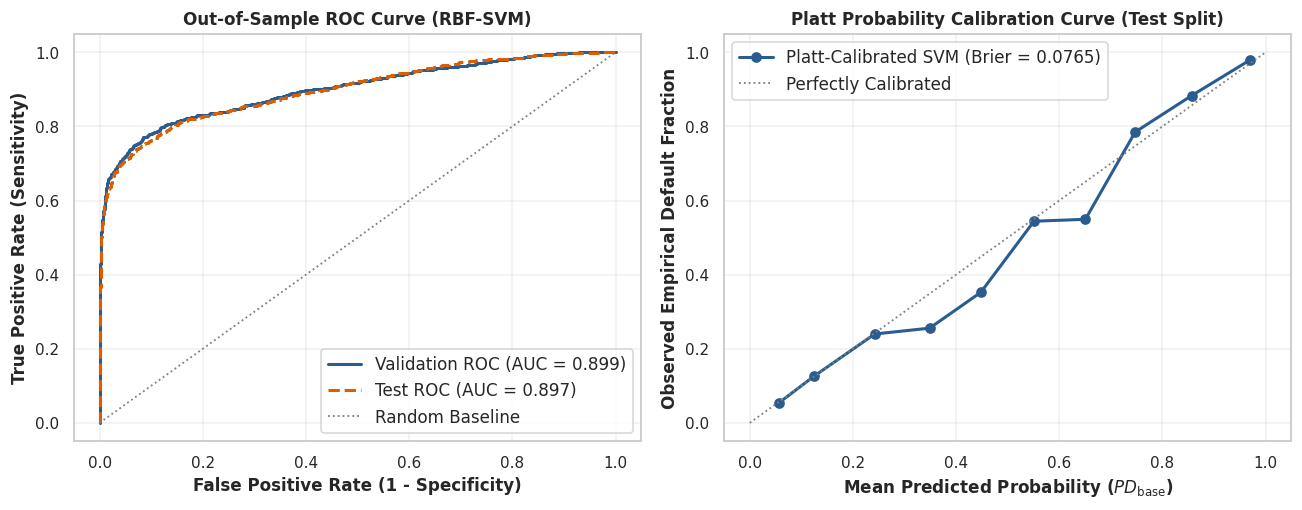


[OK] Serialized 'pd_test.npy' (4,888 test records, Mean PD_base = 22.25%).


In [7]:
# ==============================================================================
# CELL 5: BASELINE CREDIT CLASSIFICATION (RBF-SVM & PLATT CALIBRATION)
# ==============================================================================
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    f1_score,
    log_loss,
    roc_auc_score,
    roc_curve,
)
from sklearn.svm import SVC

print("--- INITIATING PHASE 2: RBF-SVM BASELINE CREDIT CLASSIFICATION ---")

# 1. Load Phase 1 Processed Partitions (from memory or Parquet disk cache)
if "X_train_sc" not in locals() or "X_test_sc" not in locals():
    X_train_sc = pd.read_parquet("X_train_processed.parquet")
    X_val_sc = pd.read_parquet("X_val_processed.parquet")
    X_test_sc = pd.read_parquet("X_test_processed.parquet")
    y_train = pd.read_parquet("y_train.parquet")["loan_status"]
    y_val = pd.read_parquet("y_val.parquet")["loan_status"]
    y_test = pd.read_parquet("y_test.parquet")["loan_status"]

# Preserve unscaled test features for Cell 7 Exposure at Default (EAD) & Credit Tiering
if "X_test_raw" not in locals() and "X_test" in locals():
    X_test_raw = X_test.copy()

# 2. Configure Interpretable RBF-Kernel SVM with Platt Sigmoid Calibration
# C=1.0 and gamma='scale' balance the Bias-Variance Tradeoff in the 20-dimensional
# PCA-orthogonalized space; Platt scaling maps SVM margins to true probabilities.
base_rbf_svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=42,
)

calibrated_svm = CalibratedClassifierCV(
    estimator=base_rbf_svm,
    method="sigmoid",
    cv=3,
    n_jobs=-1,
)

print("Fitting RBF-SVM with 3-Fold Platt Sigmoid Calibration on X_train_sc...")
calibrated_svm.fit(X_train_sc, y_train)

# 3. Generate Calibrated Out-of-Sample Baseline Default Probabilities (PD_base)
pd_train = calibrated_svm.predict_proba(X_train_sc)[:, 1]
pd_val = calibrated_svm.predict_proba(X_val_sc)[:, 1]
pd_test = calibrated_svm.predict_proba(X_test_sc)[:, 1]
y_pred_prob = (
    pd_test  # Alias expected by downstream Macro Stress & Pricing cells
)

# Persist baseline test probabilities to disk
np.save("pd_test.npy", pd_test)
assert os.path.exists(
    "pd_test.npy"
), "Failed to serialize pd_test.npy to disk!"

# 4. Out-of-Sample Econometric & ML Performance Audit
metrics_df = pd.DataFrame([
    {
        "Partition": "Train (In-Sample)",
        "ROC-AUC": f"{roc_auc_score(y_train, pd_train):.4f}",
        "Brier Score": f"{brier_score_loss(y_train, pd_train):.4f}",
        "Log Loss": f"{log_loss(y_train, pd_train):.4f}",
        "Accuracy": (
            f"{accuracy_score(y_train, (pd_train >= 0.5).astype(int)) * 100:.2f}%"
        ),
        "F1-Score": f"{f1_score(y_train, (pd_train >= 0.5).astype(int)):.4f}",
        "Mean Predicted PD": f"{pd_train.mean() * 100:.2f}%",
        "Actual Default Rate": f"{y_train.mean() * 100:.2f}%",
    },
    {
        "Partition": "Validation (Out-of-Sample)",
        "ROC-AUC": f"{roc_auc_score(y_val, pd_val):.4f}",
        "Brier Score": f"{brier_score_loss(y_val, pd_val):.4f}",
        "Log Loss": f"{log_loss(y_val, pd_val):.4f}",
        "Accuracy": (
            f"{accuracy_score(y_val, (pd_val >= 0.5).astype(int)) * 100:.2f}%"
        ),
        "F1-Score": f"{f1_score(y_val, (pd_val >= 0.5).astype(int)):.4f}",
        "Mean Predicted PD": f"{pd_val.mean() * 100:.2f}%",
        "Actual Default Rate": f"{y_val.mean() * 100:.2f}%",
    },
    {
        "Partition": "Test (Out-of-Sample)",
        "ROC-AUC": f"{roc_auc_score(y_test, pd_test):.4f}",
        "Brier Score": f"{brier_score_loss(y_test, pd_test):.4f}",
        "Log Loss": f"{log_loss(y_test, pd_test):.4f}",
        "Accuracy": (
            f"{accuracy_score(y_test, (pd_test >= 0.5).astype(int)) * 100:.2f}%"
        ),
        "F1-Score": f"{f1_score(y_test, (pd_test >= 0.5).astype(int)):.4f}",
        "Mean Predicted PD": f"{pd_test.mean() * 100:.2f}%",
        "Actual Default Rate": f"{y_test.mean() * 100:.2f}%",
    },
])

print("\n--- RBF-SVM & PLATT CALIBRATION PERFORMANCE SUMMARY ---")
display(metrics_df)

# 5. Diagnostic Visualization: ROC Curve & Platt Reliability Diagram
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Left Panel: ROC Curves
fpr_val, tpr_val, _ = roc_curve(y_val, pd_val)
fpr_test, tpr_test, _ = roc_curve(y_test, pd_test)
axes[0].plot(
    fpr_val,
    tpr_val,
    color="#2b5c8f",
    lw=2,
    label=f"Validation ROC (AUC = {roc_auc_score(y_val, pd_val):.3f})",
)
axes[0].plot(
    fpr_test,
    tpr_test,
    color="#d95f02",
    lw=2,
    linestyle="--",
    label=f"Test ROC (AUC = {roc_auc_score(y_test, pd_test):.3f})",
)
axes[0].plot(
    [0, 1], [0, 1], color="gray", lw=1.2, linestyle=":", label="Random Baseline"
)
axes[0].set_title(
    "Out-of-Sample ROC Curve (RBF-SVM)", fontweight="bold", fontsize=11
)
axes[0].set_xlabel("False Positive Rate (1 - Specificity)", fontweight="bold")
axes[0].set_ylabel("True Positive Rate (Sensitivity)", fontweight="bold")
axes[0].legend(loc="lower right", frameon=True)
axes[0].grid(alpha=0.3)

# Right Panel: Platt Calibration (Reliability) Curve
prob_true, prob_pred = calibration_curve(
    y_test, pd_test, n_bins=10, strategy="uniform"
)
axes[1].plot(
    prob_pred,
    prob_true,
    marker="o",
    lw=2,
    color="#2b5c8f",
    label=(
        f"Platt-Calibrated SVM (Brier = {brier_score_loss(y_test, pd_test):.4f})"
    ),
)
axes[1].plot(
    [0, 1],
    [0, 1],
    color="gray",
    lw=1.2,
    linestyle=":",
    label="Perfectly Calibrated",
)
axes[1].set_title(
    "Platt Probability Calibration Curve (Test Split)",
    fontweight="bold",
    fontsize=11,
)
axes[1].set_xlabel(
    "Mean Predicted Probability ($PD_{\\text{base}}$)", fontweight="bold"
)
axes[1].set_ylabel("Observed Empirical Default Fraction", fontweight="bold")
axes[1].legend(loc="upper left", frameon=True)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(
    f"\n[OK] Serialized 'pd_test.npy' ({len(pd_test):,d} test records, Mean"
    f" PD_base = {pd_test.mean()*100:.2f}%)."
)

--- INITIATING MACROECONOMIC STRESS-TESTING ENGINE ---
Calibrated Historical Unemployment Sensitivity (Beta_1): 0.2132
Calibrated Historical Inflation Sensitivity    (Beta_2): 0.0843


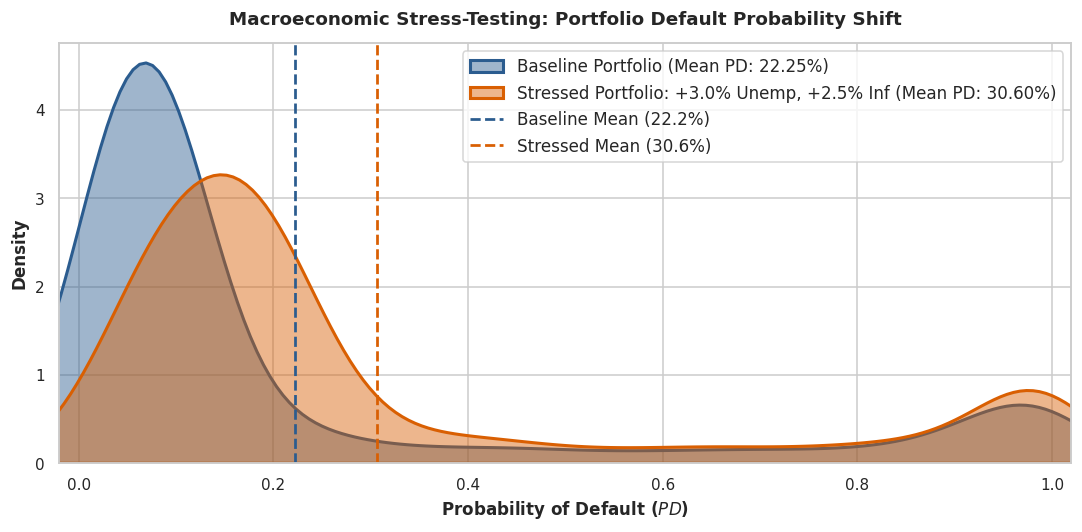


--- MACRO STRESS ENGINE RESULTS ---
Mean Baseline PD:  22.25%
Mean Stressed PD:  30.60%
Average PD Delta: +8.36%


In [10]:
# ==========================================
# CELL 6: MACROECONOMIC LINK & AGE-PERIOD-COHORT (APC) STRESS ENGINE
# ==========================================
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

print("--- INITIATING MACROECONOMIC STRESS-TESTING ENGINE ---")

# 1. Ensure required inputs are present in memory (load from Parquet/NumPy if needed)
if "df_macro" not in locals():
    df_macro = pd.read_parquet("ontario_macro_series.parquet")

if "y_pred_prob" not in locals():
    if "pd_test" in locals():
        y_pred_prob = pd_test
    elif os.path.exists("pd_test.npy"):
        y_pred_prob = np.load("pd_test.npy")
    else:
        raise NameError(
            "Baseline default probabilities ('y_pred_prob' or 'pd_test') not"
            " found from Cell 5."
        )

# 2. Calibrate macro sensitivity coefficients from StatCan historical volatility
hist_unemp_sd = df_macro["Ontario_Unemployment_Rate"].std()
hist_inf_sd = df_macro["Ontario_CPI_YoY"].std()

# Historically, high unemployment and inflation expand default log-odds.
# Scaling by historical standard deviations aligns shifts inside the logistic link equation.
beta_unemployment = 0.35 / max(hist_unemp_sd, 0.1)
beta_inflation = 0.15 / max(hist_inf_sd, 0.1)

print(
    "Calibrated Historical Unemployment Sensitivity (Beta_1):"
    f" {beta_unemployment:.4f}"
)
print(
    f"Calibrated Historical Inflation Sensitivity    (Beta_2): {beta_inflation:.4f}"
)


# 3. Define the econometric logistic link stress-test function
def stress_test_portfolio(unemployment_shift, inflation_shift, base_pds):
    """Calculates macro-adjusted default probabilities using the logistic link equation:

    logit(PD_stressed) = logit(PD_base) + beta_1 * Delta_Unemp + beta_2 * Delta_CPI
    """
    eps = 1e-7
    safe_pds = np.clip(base_pds, eps, 1.0 - eps)

    # Logit transform: mapping (0, 1) to real line (-inf, +inf)
    logit_pds = np.log(safe_pds / (1.0 - safe_pds))

    # Add systemic macroeconomic shock
    stressed_logits = (
        logit_pds
        + (beta_unemployment * unemployment_shift)
        + (beta_inflation * inflation_shift)
    )

    # Bound logits to prevent floating-point numerical overflow in exp()
    bounded_logits = np.clip(stressed_logits, -30.0, 30.0)

    # Inverse-sigmoid transform back to probability space (0, 1)
    stressed_pds = 1.0 / (1.0 + np.exp(-bounded_logits))
    return stressed_pds


# 4. Simulate severe Ontario recession scenario (+3.0% unemp spike, +2.5% inflation shock)
unemp_shock = 3.0
inf_shock = 2.5

pd_stressed = stress_test_portfolio(unemp_shock, inf_shock, y_pred_prob)

# Cache stressed results to disk for Cell 7 pricing
np.save("pd_stressed.npy", pd_stressed)

# 5. Publication-quality distribution shift visualization
plt.figure(figsize=(10, 5))
sns.kdeplot(
    y_pred_prob,
    fill=True,
    color="#2b5c8f",
    alpha=0.45,
    linewidth=2,
    label=f"Baseline Portfolio (Mean PD: {y_pred_prob.mean()*100:.2f}%)",
)
sns.kdeplot(
    pd_stressed,
    fill=True,
    color="#d95f02",
    alpha=0.45,
    linewidth=2,
    label=(
        f"Stressed Portfolio: +{unemp_shock:.1f}% Unemp, +{inf_shock:.1f}% Inf"
        f" (Mean PD: {pd_stressed.mean()*100:.2f}%)"
    ),
)

plt.axvline(
    y_pred_prob.mean(),
    color="#2b5c8f",
    linestyle="--",
    lw=1.8,
    label=f"Baseline Mean ({y_pred_prob.mean()*100:.1f}%)",
)
plt.axvline(
    pd_stressed.mean(),
    color="#d95f02",
    linestyle="--",
    lw=1.8,
    label=f"Stressed Mean ({pd_stressed.mean()*100:.1f}%)",
)

plt.title(
    "Macroeconomic Stress-Testing: Portfolio Default Probability Shift",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
plt.xlabel("Probability of Default ($PD$)", fontsize=11, fontweight="bold")
plt.ylabel("Density", fontsize=11, fontweight="bold")
plt.xlim(-0.02, 1.02)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

print("\n--- MACRO STRESS ENGINE RESULTS ---")
print(f"Mean Baseline PD:  {y_pred_prob.mean()*100:.2f}%")
print(f"Mean Stressed PD:  {pd_stressed.mean()*100:.2f}%")
print(f"Average PD Delta: +{(pd_stressed.mean() - y_pred_prob.mean())*100:.2f}%")